## 0. 설정

In [1]:
import sys
sys.path.append("..")                                   # 상위 폴더의 config.py를 불러오기 위해 경로 추가
import pandas as pd
from google.cloud import bigquery
import pydata_google_auth
from config import PROJECT_ID, LOCATION, MAX_BYTES_BILLED

# BigQuery 연결 (처음 한 번 로그인하면 이후에는 저장된 인증 정보 재사용)
credentials = pydata_google_auth.get_user_credentials(["https://www.googleapis.com/auth/bigquery"])
client = bigquery.Client(project=PROJECT_ID, credentials=credentials, location=LOCATION,
                         default_query_job_config=bigquery.QueryJobConfig(maximum_bytes_billed=MAX_BYTES_BILLED))

def query(sql):
    """SQL 문자열을 BigQuery에서 실행하고 결과를 DataFrame으로 돌려줌"""
    return client.query(sql).to_dataframe(create_bqstorage_client=False)

pd.set_option("display.max_rows", 100)                  # 일별 결과(56행 이상)가 생략되지 않고 다 보이도록

# 02. 데이터 품질 점검

- 목적: 이벤트 로그 등 상세 데이터를 분석에 쓰기 전에, 빠지거나 겹치거나 이상한 부분이 없는지 확인
- 대상: BigQuery `raw` 데이터셋 (수정하지 않고 조회만 함)
- 점검 결과로 정한 정제 방법은 `sql/stg/`에 반영

## 1. 날짜 확인

### 1-1) 일별 누락 날짜가 있는지 확인 (events, orders)

### events 테이블 누락일자 여부 확인

<Axes: xlabel='event_date'>

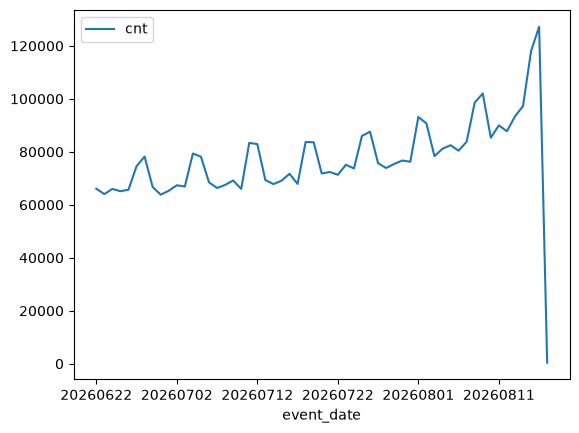

In [2]:
## event : 일별 누락 날짜가 있는지 (events, order)

df = query("""
    SELECT 
      event_date
      ,count(*) cnt
    FROM raw.events
    group by 1
    order by 1
""")
df.plot(x="event_date", y="cnt")



#### 날짜 수·빠진 날짜, 마지막 날 이벤트 시간대
- 첫날~마지막 날 전체 날짜와 비교해 빠진 날짜를 찾음
- 마지막 날(8/17) 건수가 유독 적어서, 이벤트가 몇 시에 찍혔는지 KST로 바꿔 확인

In [3]:
# 1) 날짜 수와 빠진 날짜
dates = pd.to_datetime(df["event_date"], format="%Y%m%d")
print(len(df), dates.min().date(), dates.max().date())
full = pd.date_range(dates.min(), dates.max())   # 첫날~마지막 날 전체 날짜
print("빠진 날짜:", full.difference(dates))       # 비어 있으면 누락 없음

# 2) 마지막 날 이벤트가 몇 시에 찍혔는지 (UTC → KST로 바꿔서 확인)
query("""
SELECT
  EXTRACT(HOUR FROM DATETIME(TIMESTAMP_MICROS(event_timestamp), 'Asia/Seoul')) AS kst_hour
  ,COUNT(*) AS cnt
FROM raw.events
WHERE event_date = (SELECT MAX(event_date) FROM raw.events)
GROUP BY 1 ORDER BY 1
""")

57 2026-06-22 2026-08-17
빠진 날짜: DatetimeIndex([], dtype='datetime64[us]', freq='D')


,kst_hour,cnt
0,0,396


### 1-2) 마지막 주 급등 원인 확인
- 이벤트 종류별 주간 건수를 비교 (8/17은 제외)
- 특정 이벤트 하나만 늘었다면 로깅 오류를, 모든 이벤트가 같이 늘었다면 유입 증가를 의심

In [4]:
df2 = query(""" 
    SELECT
      DATE_TRUNC(PARSE_DATE("%Y%m%d", event_date), WEEK(MONDAY)) AS week   -- 월요일 시작 주
      ,event_name
      ,COUNT(*) AS cnt
    FROM raw.events
    WHERE event_date <= "20260816"
    GROUP BY 1, 2
    ORDER BY 2, 1
""")

df2.pivot(index = "event_name", columns = "week", values = "cnt")


week,2026-06-22,2026-06-29,2026-07-06,2026-07-13,2026-07-20,2026-07-27,2026-08-03,2026-08-10
event_name,,,,,,,,
add_payment_info,6007,5985,6143,6168,6460,6712,7040,8047
add_shipping_info,6166,6144,6291,6343,6664,6880,7252,8312
add_to_cart,30616,30773,31155,31667,32681,33802,35755,40026
begin_checkout,6344,6381,6482,6562,6846,7110,7487,8533
click_continue_shopping,1431,1450,1491,1550,1718,1802,1944,2373
login,6626,7365,8068,8842,9653,10518,12174,15156
open_option_selector,44845,45010,47116,47292,49716,52197,56036,64127
purchase,5955,5906,6055,6087,6407,6628,6941,7942
search,29441,29439,30567,31067,32467,34033,36738,41820


#### 결과 (events)
- 6/22~8/17, 57일, 빠진 날짜 없음
- 8/17은 0시 이벤트 396건뿐 → 8/16 밤 세션이 자정을 넘기며 찍힌 것. 데이터가 잘린 것이 아님
- 마지막 주 급등은 모든 이벤트가 함께 늘어난 **유입 증가** (8주간 session_start +55%, sign_up 452 → 3,944). 오류 아님
- 퍼널 순서(장바구니 > 주문 시작 > 배송지 > 결제수단 > 구매)가 매주 유지됨
- 참고: 세션 +55%에 비해 구매는 +33% → 전환율 하락. 품질 문제가 아니라 분석 대상이므로 퍼널 분석(Q4)에서 확인

### orders 테이블 누락일자 여부 확인

<Axes: xlabel='order_date'>

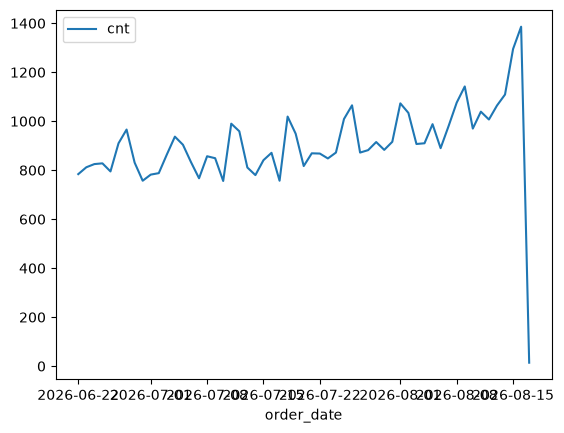

In [5]:
df_orders = query("""
    SELECT 
      date(order_datetime) order_date
      ,count(*) cnt
    FROM raw.orders
    group by 1
    order by 1
""")
#df_orders
df_orders.plot(x="order_date", y="cnt")

In [6]:
# 1) 날짜 수와 빠진 날짜
dates_order = pd.to_datetime(df_orders["order_date"], format="%Y%m%d")
print(len(df_orders), dates_order.min().date(), dates_order.max().date())
full_order = pd.date_range(dates_order.min(), dates_order.max())   # 첫날~마지막 날 전체 날짜
print("빠진 날짜:", full_order.difference(dates_order))       # 비어 있으면 누락 없음

# 2) 마지막 날 이벤트가 몇 시에 찍혔는지 
query("""
SELECT
  EXTRACT(HOUR FROM order_datetime) AS kst_hour,
  COUNT(*) AS cnt
FROM raw.orders
WHERE DATE(order_datetime) = (select max(DATE(order_datetime)) from raw.orders )  
GROUP BY 1
ORDER BY 1
""")

57 2026-06-22 2026-08-17
빠진 날짜: DatetimeIndex([], dtype='datetime64[s]', freq='D')


,kst_hour,cnt
0,0,14


#### 결과 (orders)
- 6/22~8/17, 57일, 빠진 날짜 없음. 주말 주기·마지막 주 상승이 events와 같음
- 8/17 주문 14건이 모두 0시 → events와 같은 이유 (전날 밤 세션의 결제)

### 1번 결론
- **문제 없음.** 분석 기간은 **2026-06-22 ~ 2026-08-16 (8주, 56일)**
- 8/17 0시 데이터는 앞날 세션에 이어진 것이므로, 세션 단위로 볼 때는 버리지 않고 포함

## 2. 키 중복 확인
- 각 테이블의 키가 유일하고 비어 있지 않은지 확인
- events는 이벤트 로그라 고유 키가 없어 제외 (구매 이벤트 중복은 4번에서 확인)

### 2-1) 테이블별 행 수·컬럼 수
- 데이터는 읽지 않고 테이블 정보만 가져와서 처리량이 0

In [7]:
# 전체 테이블 목록
TABLES = ["events", "users", "products", "orders", "order_items", "returns", "kpi_monthly"]

rows = []
for name in TABLES:
    table = client.get_table(f"{PROJECT_ID}.raw.{name}")   # 데이터는 읽지 않고 테이블 정보만 가져옴 (처리량 0)
    rows.append({"table": name, "n_rows": table.num_rows, "n_cols": len(table.schema)})

table_size = pd.DataFrame(rows)
table_size


,table,n_rows,n_cols
0,events,4390472,12
1,users,100000,6
2,products,587,8
3,orders,51523,9
4,order_items,144768,5
5,returns,5370,7
6,kpi_monthly,19,11


### 2-2) 키 중복·결측 확인
- `n_duplicated` = 전체 행 수 − 고유 키 수, `n_null` = 키가 비어 있는 행 수
- 둘 다 0이면 `ok = True`

In [8]:
# 키 중복, 결측 검정 

# 유일해야하는 키 (테이블 이름 → 키 컬럼 목록)

KEYS = {
    "users" : ["user_id"],
    "products" : ["item_id"],
    "orders": ["order_id"],
    "order_items" : ["order_id","item_id"],
    "returns": ["return_id"],
    "kpi_monthly" : ["month"],
}

results = []
for table, cols in KEYS.items():
    # 키 컬럼들을 하나의 값으로 묶음
    # 컬럼 1개 -> 그대로 / 컬럼 여러개 -> TO_JSON_STRING(STRUCT(...))로 한 문자열로 만들어 조합 단위로 셈 
    key_expr = cols[0] if len(cols) == 1 else f"TO_JSON_STRING(STRUCT({', '.join(cols)}))"
    # 키 컬럼 중 하나라도 비어 있는 행 
    null_expr = " or ".join(f"{c} IS NULL" for c in cols)

    df = query(f""" 
                select
                    '{table}'   as table_name,
                    '{" + ".join(cols)}'    AS key_columns,
                    count(*)                AS n_rows,
                    count(distinct {key_expr}) AS n_unique,
                    countif({null_expr})       AS n_null,
                from raw.{table}

    
                            """)
    results.append(df)    

key_check = pd.concat(results, ignore_index=True)
key_check["n_duplicated"] = key_check["n_rows"] - key_check["n_unique"]   #중복된 행 수 
key_check["ok"] = (key_check["n_duplicated"] ==0) & (key_check["n_null"] == 0)
key_check





,table_name,key_columns,n_rows,n_unique,n_null,n_duplicated,ok
0,users,user_id,100000,100000,0,0,True
1,products,item_id,587,587,0,0,True
2,orders,order_id,51523,51523,0,0,True
3,order_items,order_id + item_id,144768,144760,0,8,False
4,returns,return_id,5370,5370,0,0,True
5,kpi_monthly,month,19,19,0,0,True


### 2-3) order_items 중복 행 상세
- 2-2)에서 order_items만 주문+상품 조합이 8건 겹침 → 겹치는 행을 직접 확인

In [9]:
dup_items = query(""" 
        with dup_keys as (
          SELECT 
            order_id,
            item_id
          FROM raw.order_items
          group by 1,2 
          having count(*) > 1
        )
        select oi.*
          from raw.order_items oi
          inner
          join dup_keys dk
            on dk.order_id = oi.order_id
           and dk.item_id = oi.item_id 
         order 
            by dk.order_id
""")

print(dup_items)

## 분석 시 order_id, item_id, price 기준으로 sum(quantity) 해서 활용. 

    order_id item_id  price  quantity add_source
0   T0015379   P0469   5900         1       list
1   T0015379   P0469   5900         1    product
2   T0015877   P0238  16500         1       list
3   T0015877   P0238  16500         1    product
4   T0016868   P0578   3400         1       list
5   T0016868   P0578   3400         1    product
6   T0017202   P0363   8900         1       list
7   T0017202   P0363   8900         1    product
8   T0021010   P0374  11700         1       list
9   T0021010   P0374  11700         1    product
10  T0042372   P0508  16800         1       list
11  T0042372   P0508  16800         1    product
12  T0043478   P0258  14300         1       list
13  T0043478   P0258  14300         1    product
14  T0049093   P0451   7200         1       list
15  T0049093   P0451   7200         1    product


#### 결과
- 5개 테이블(users, products, orders, returns, kpi_monthly)은 중복·결측 0
- order_items의 중복 8쌍은 `add_source`(list / product)만 다른 두 줄 → 같은 상품을 목록 화면과 상세 화면에서 따로 담은 것. **오류가 아님**
- 실제 키는 **주문 + 상품 + 담은 경로**. 행은 지우지 않고, 상품 단위로 볼 때 `GROUP BY order_id, item_id` + `SUM(quantity)`로 합산
- 8쌍 모두 list + product 조합 → 무료배송 금액을 채우는 행동을 분석할 때 참고

### 2번 결론
- **문제 없음.** order_items의 키 정의만 문서(04)에 반영

## 3. user_id 결측 확인
- user_id가 빈 이벤트 비율
- 이벤트 종류별 비율  
- 같은 세션 안에서 나중에 채워지는지

### 3-1) user_id가 빈 이벤트 비율

In [10]:
query(''' 
SELECT 
  count(*)  AS cnt,
  countif(user_id is null) as null_cnt,
  round(countif(user_id is null) /count(*)*100,4) as ratio_cnt
FROM 
  raw.events 
where 
  1=1;

''')

,cnt,null_cnt,ratio_cnt
0,4390472,419737,9.5602


#### 결과
- 전체 이벤트 4,390,472건 중 419,737건(**약 9.6%**)이 user_id 없음
- 무시하기엔 큰 규모 → 어디서, 왜 비는지 확인

### 3-2) 이벤트 종류별 결측 비율 
- 로그인 전 이벤트는 비어있는게 정상, 로그인 후 이벤트가 비어있으면 문제

In [11]:
query('''
SELECT 
  event_name,
  count(*)  AS cnt,
  countif(user_id is null) as null_cnt,
  round(countif(user_id is null) /count(*)*100,4) as ratio_cnt
FROM 
  raw.events 
where 
  1=1
GROUP by 
  event_name
''')

,event_name,cnt,null_cnt,ratio_cnt
0,view_cart,95632,0,0.0000
1,search_review,62420,7051,11.2961
2,sign_up,18151,0,0.0000
3,add_to_cart,266508,0,0.0000
4,session_start,344287,65758,19.0998
5,select_item,711868,70347,9.8820
6,view_item_list,723980,78571,10.8526
7,view_review,263316,28403,10.7867
8,select_option,213977,24574,11.4844
9,begin_checkout,55760,0,0.0000


#### 결과
- 결측은 **둘러보기 이벤트에만** 있음: session_start 19.1%, 목록·상품 조회·검색·리뷰·옵션 선택 약 10~11%
- **장바구니 담기부터 구매까지(add_to_cart, view_cart, begin_checkout, 배송지·결제수단 입력, purchase)는 0%** → 장바구니부터는 로그인이 필요하다는 서비스 구조와 맞음
- login, sign_up도 0% → 로그인하는 순간부터 user_id가 붙음
- purchase에 결측이 없어서 구매·매출 집계에는 영향 없음

### 3-3) 세션 단위로 확인. 

- 이벤트 종류만으로는 "로그인 전이라 비어 있는 것"인지 확신할 수 없어 세션 단위로 확인
- 세션 = 기기(`user_pseudo_id`) + 세션 번호(`ga_session_id`)
- 세션을 전부 채워짐 / 섞임 / 전부 비어 있음으로 나누고, 섞인 세션이 "비어 있다가 나중에 채워진" 것인지 확인

In [12]:
# 3-3) 세션 단위로 보기: 세션 안에서 user_id가 어떻게 비어 있는지
# 세션 = 기기(user_pseudo_id) + 세션 번호(ga_session_id)
query("""
WITH e AS (
  SELECT
    user_pseudo_id,
    (SELECT value.int_value FROM UNNEST(event_params) WHERE key = 'ga_session_id') AS session_id,
    event_timestamp,
    user_id
  FROM raw.events
),
s AS (   -- 세션별 요약
  SELECT
    user_pseudo_id,
    session_id,
    COUNT(*)                                          AS n_events,
    COUNTIF(user_id IS NULL)                          AS n_null,
    COUNT(DISTINCT user_id)                           AS n_user_ids,        -- 세션 안의 서로 다른 user_id 수 (NULL 제외)
    MIN(IF(user_id IS NOT NULL, event_timestamp, NULL)) AS first_filled_ts, -- 처음 채워진 시각
    MAX(IF(user_id IS NULL, event_timestamp, NULL))     AS last_null_ts     -- 마지막으로 비어 있던 시각
  FROM e
  GROUP BY 1, 2
)
SELECT
  CASE
    WHEN n_null = 0        THEN '1_전부 채워짐'
    WHEN n_null = n_events THEN '3_전부 비어 있음'
    ELSE                        '2_섞임'
  END                                                         AS session_type,
  COUNT(*)                                                    AS n_sessions,
  SUM(n_null)                                                 AS n_null_events,
  COUNTIF(last_null_ts < first_filled_ts)                     AS n_null_then_filled,  -- 비어 있다가 이후 채워진 세션
  COUNTIF(n_user_ids > 1)                                     AS n_multi_user         -- 한 세션에 user_id가 2개 이상 (있으면 이상)
FROM s
GROUP BY 1
ORDER BY 1
""")

,session_type,n_sessions,n_null_events,n_null_then_filled,n_multi_user
0,1_전부 채워짐,278529,0,0,0
1,2_섞임,65758,419737,65758,0


#### 결과
- 전체 세션 344,287개 중 65,758개(**약 19%**)가 섞인 세션이고, **모두** 비어 있다가 이후 채워짐(`n_sessions` = `n_null_then_filled`) → 원인은 **로그인 전 이벤트에 user_id가 안 붙는 구조**
- 전부 비어 있는 세션 0개 → 모든 결측 이벤트가 같은 세션 안에 user_id를 갖고 있어 **100% 복구 가능**
- 한 세션에 user_id가 2개 이상인 경우 0 → 세션의 user_id로 채워도 틀릴 일 없음
- 데이터 한계: 끝까지 로그인하지 않은 세션(비회원 둘러보기)이 없음. 실제 서비스라면 존재할 것

#### 정제 방법 (stg에 반영)
```sql
COALESCE(user_id, MAX(user_id) OVER (PARTITION BY user_pseudo_id, session_id)) AS user_id_filled
```
- 원래 user_id는 남기고 `user_id_filled`를 새 컬럼으로 추가 → 로그인 시점 분석에도 활용 가능

#### 남은 것
- 3-4) 고객 유형별 결측 비율: 결측이 신규 고객에게 몰려 있는지 확인 (보정하지 않으면 신규 행동이 적게 잡힘)